# 04. Q2 배송 지연이 평점과 불만 유형에 미치는 영향

**질문**: 배송 지연은 평점과 불만 유형에 얼마나 영향을 주는가?

- 단위: 주문. `v_orders` 중 배송 지표 대상 주문(`exclude_delivery_metrics = 0`, delivered이고 날짜가 정상인 주문)과 `v_order_reviews`(주문당 대표 리뷰)
- 지연: `delay_days` = 예상 배송일 → 고객 수령일(날짜 단위, 양수면 지연). `is_late` = `delay_days > 0`
- 쿼리: `sql/analysis/q2_*.sql` / 차트: `reports/figures/q2_*.png` / 결과 정리: `reports/analysis/q2_delivery_delay.md`

표본이 약 9만 6천 건이라 p값은 거의 항상 매우 작다. **효과 크기와 오즈비 중심으로 해석한다.**

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from IPython.display import display
from scipy.stats import mannwhitneyu
from sqlalchemy import text
from statsmodels.stats.proportion import confint_proportions_2indep, proportions_ztest


def find_project_root(start: Path) -> Path:
    """sql/analysis 폴더가 있는 프로젝트 루트를 찾는다."""
    for path in [start, *start.parents]:
        if (path / "sql" / "analysis").is_dir():
            return path
    raise FileNotFoundError("프로젝트 루트를 찾지 못함")


ROOT = find_project_root(Path.cwd())
SQL_DIR = ROOT / "sql" / "analysis"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / "src" / "etl"))
from db import get_engine  # noqa: E402

engine = get_engine()

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)

BUCKETS = ["7일 이상 빠름", "1~6일 빠름", "예상일 당일", "1~3일 지연", "4~7일 지연", "8~14일 지연", "15일 이상 지연"]
OWNER_COLS = {
    "share_logistics": ("물류", "#d62728"), "share_seller_fulfillment": ("판매자 출고", "#ff7f0e"),
    "share_product": ("상품", "#1f77b4"), "share_seller_service": ("판매자 응대", "#9467bd"),
    "share_platform": ("플랫폼 정책", "#8c564b"), "share_other": ("기타", "#7f7f7f"),
    "share_no_complaint": ("불만 없음", "#2ca02c"),
}


def run_sql(name: str) -> pd.DataFrame:
    """sql/analysis의 SQL 파일을 실행해 DataFrame으로 돌려준다(DECIMAL은 float로)."""
    df = pd.read_sql(text((SQL_DIR / name).read_text(encoding="utf-8")), engine)
    for c in df.columns:
        if df[c].dtype == object and df[c].map(lambda v: hasattr(v, "as_tuple")).any():
            df[c] = df[c].astype(float)
    return df


def pct(df: pd.DataFrame, cols: list[str]) -> pd.DataFrame:
    """비율 컬럼을 % 문자열로 바꾼 표시용 사본."""
    out = df.copy()
    for c in cols:
        out[c] = (out[c].astype(float) * 100).map(lambda v: "" if pd.isna(v) else f"{v:.1f}%")
    return out


def save(fig, name: str) -> None:
    """차트를 reports/figures에 저장한다."""
    fig.savefig(FIG_DIR / name, bbox_inches="tight")
    print(f"저장: reports/figures/{name}")

## 1. 지연 구간별 평점

평균 평점, 1~2점(저평점) 비율, 5점 비율을 지연 구간별로 본다. 대부분의 주문은 예상일보다 일찍 도착한다(예상 배송일이 넉넉하게 잡혀 있음).

,delay_bucket,n_orders,주문 비중,n_reviewed,avg_score,low_score_share,five_score_share
0,7일 이상 빠름,76117,78.9%,75721,4.31,9.0%,63.3%
1,1~6일 빠름,12504,13.0%,12419,4.18,10.6%,56.8%
2,예상일 당일,1292,1.3%,1280,4.03,12.4%,50.6%
3,1~3일 지연,1870,1.9%,1852,3.29,32.1%,33.1%
4,4~7일 지연,1802,1.9%,1748,2.10,67.6%,14.1%
5,8~14일 지연,1478,1.5%,1446,1.67,80.2%,6.9%
6,15일 이상 지연,1384,1.4%,1335,1.72,78.3%,7.2%


저장: reports/figures/q2_score_by_delay.png


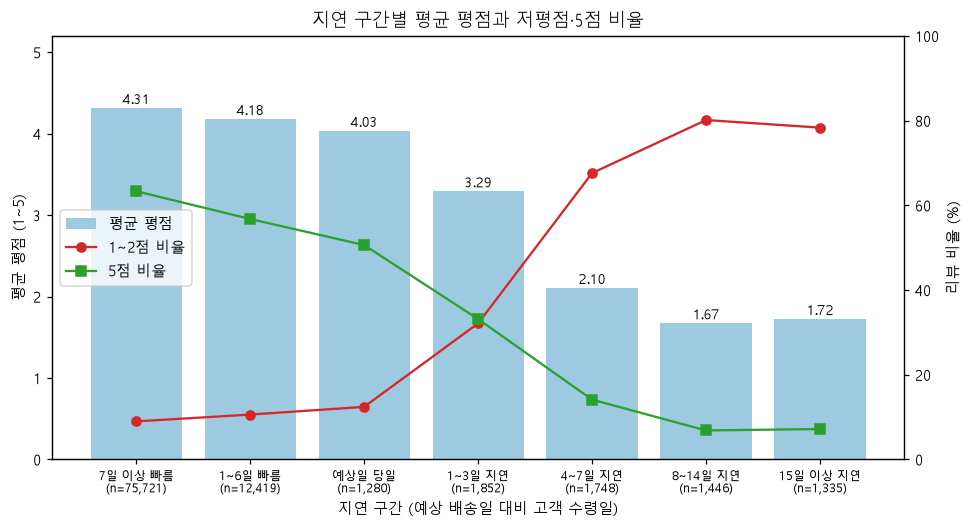

In [2]:
scores = run_sql("q2_01_delay_bucket_scores.sql")
scores["주문 비중"] = scores["n_orders"] / scores["n_orders"].sum()
display(pct(scores[["delay_bucket", "n_orders", "주문 비중", "n_reviewed", "avg_score", "low_score_share", "five_score_share"]]
            .round({"avg_score": 2}), ["주문 비중", "low_score_share", "five_score_share"]))

fig, ax1 = plt.subplots(figsize=(10, 5))
x = np.arange(len(scores))
ax1.bar(x, scores["avg_score"], color="#9ecae1", label="평균 평점")
for i, v in enumerate(scores["avg_score"]):
    ax1.text(i, v + 0.05, f"{v:.2f}", ha="center", fontsize=9)
ax1.set_ylim(0, 5.2)
ax1.set_ylabel("평균 평점 (1~5)")
ax1.set_xticks(x, [f"{b}\n(n={n:,})" for b, n in zip(scores["delay_bucket"], scores["n_reviewed"])], fontsize=8)
ax2 = ax1.twinx()
ax2.plot(x, scores["low_score_share"] * 100, color="#d62728", marker="o", label="1~2점 비율")
ax2.plot(x, scores["five_score_share"] * 100, color="#2ca02c", marker="s", label="5점 비율")
ax2.set_ylim(0, 100)
ax2.set_ylabel("리뷰 비율 (%)")
lines = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
ax1.legend(lines, ["평균 평점", "1~2점 비율", "5점 비율"], loc="center left")
ax1.set_xlabel("지연 구간 (예상 배송일 대비 고객 수령일)")
ax1.set_title("지연 구간별 평균 평점과 저평점·5점 비율")
save(fig, "q2_score_by_delay.png")
plt.show()

## 2. 지연 구간별 불만 구성

분류된 리뷰(텍스트 있는 1~3점)가 있는 주문만 본다. 개선 주체 비중은 주 원인 기준(Q1과 같은 묶음), DELAY·NOT_RECEIVED 비율은 다중 라벨 기준이다.

,delay_bucket,n_classified,물류,판매자 출고,상품,판매자 응대,플랫폼 정책,기타,불만 없음,delay_rate,not_received_rate
0,7일 이상 빠름,7864,11.9%,33.6%,36.2%,3.0%,2.2%,3.2%,9.8%,7.3%,8.2%
1,1~6일 빠름,1506,17.9%,26.2%,34.3%,2.3%,5.4%,4.0%,10.0%,15.5%,8.0%
2,예상일 당일,187,27.8%,21.9%,28.9%,1.6%,7.5%,4.8%,7.5%,24.6%,9.6%
3,1~3일 지연,539,59.0%,12.6%,13.4%,3.5%,4.3%,3.5%,3.7%,48.0%,38.2%
4,4~7일 지연,888,82.4%,2.9%,3.0%,5.7%,1.5%,2.9%,1.5%,54.0%,64.4%
5,8~14일 지연,859,84.8%,1.2%,1.2%,6.2%,1.1%,4.4%,1.3%,53.4%,67.0%
6,15일 이상 지연,811,84.2%,1.4%,1.5%,7.1%,1.0%,3.7%,1.1%,53.0%,66.5%


저장: reports/figures/q2_owner_by_delay.png


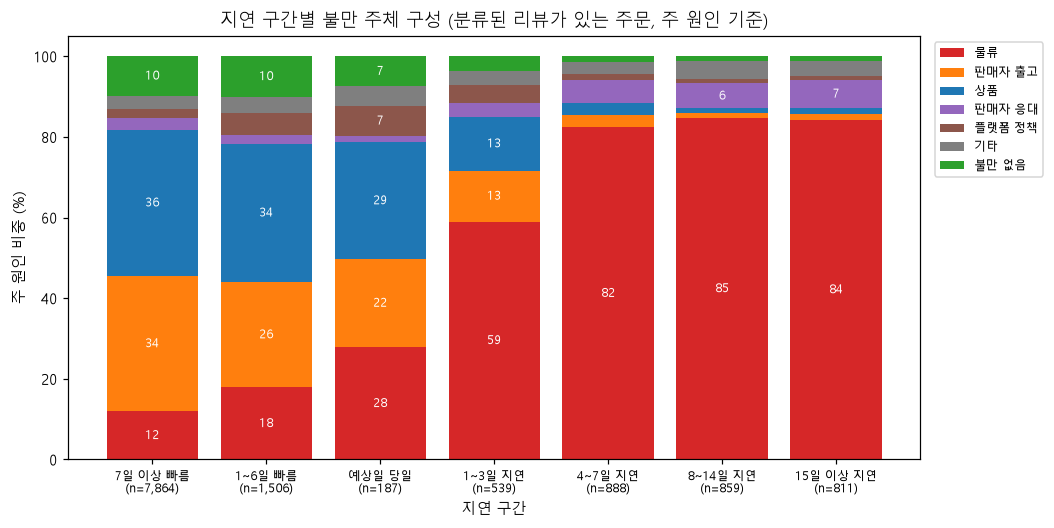

In [3]:
complaints = run_sql("q2_02_delay_bucket_complaints.sql")
show_cols = ["delay_bucket", "n_classified"] + list(OWNER_COLS) + ["delay_rate", "not_received_rate"]
display(pct(complaints[show_cols].rename(columns={k: v[0] for k, v in OWNER_COLS.items()}),
            [v[0] for v in OWNER_COLS.values()] + ["delay_rate", "not_received_rate"]))

fig, ax = plt.subplots(figsize=(10, 5))
bottom = np.zeros(len(complaints))
for col, (name, color) in OWNER_COLS.items():
    vals = complaints[col].to_numpy() * 100
    ax.bar(complaints["delay_bucket"], vals, bottom=bottom, label=name, color=color)
    for i, (v, b) in enumerate(zip(vals, bottom)):
        if v >= 6:
            ax.text(i, b + v / 2, f"{v:.0f}", ha="center", va="center", color="white", fontsize=8)
    bottom += vals
ax.set_xticks(range(len(complaints)), [f"{b}\n(n={n:,})" for b, n in zip(complaints["delay_bucket"], complaints["n_classified"])], fontsize=8)
ax.set_ylabel("주 원인 비중 (%)")
ax.set_xlabel("지연 구간")
ax.set_title("지연 구간별 불만 주체 구성 (분류된 리뷰가 있는 주문, 주 원인 기준)")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
save(fig, "q2_owner_by_delay.png")
plt.show()

## 3. 고객이 인식한 지연 vs 실제 지연

- DELAY 불만이 붙은 주문 중 실제로 지연된 비율과 예상일 이내에 받은 비율
- 실제로 지연된 주문 중 리뷰에서 DELAY(또는 아직 못 받았다는 NOT_RECEIVED)를 언급한 비율
- 제때 받았는데도 DELAY 불만을 쓴 주문은 어떤 주문인지: 배송 소요 일수와 약속 배송 기간(구매 → 예상 배송일)을 전체 주문과 비교

DELAY 불만 주문 2,481건: 실제 지연 65.6% / 예상일 이내 수령 34.4%
실제 지연 주문(분류 리뷰 있음) 3,097건: DELAY 언급 52.6% / NOT_RECEIVED 언급 61.1% / 둘 중 하나 81.2%


,배송 소요 count,배송 소요 25%,배송 소요 50%,배송 소요 75%,배송 소요 mean,약속 기간 count,약속 기간 25%,약속 기간 50%,약속 기간 75%,약속 기간 mean
grp,,,,,,,,,,
DELAY 불만 + 제때 수령,853.0,11.3,17.8,23.4,18.0,853.0,22.0,26.6,32.5,28.0
DELAY 불만 + 실제 지연,1628.0,27.8,34.3,42.4,36.7,1628.0,19.7,23.4,28.0,23.7
그 외,93966.0,6.7,10.1,15.2,12.1,93966.0,18.3,23.2,28.4,23.7


저장: reports/figures/q2_perceived_vs_actual.png


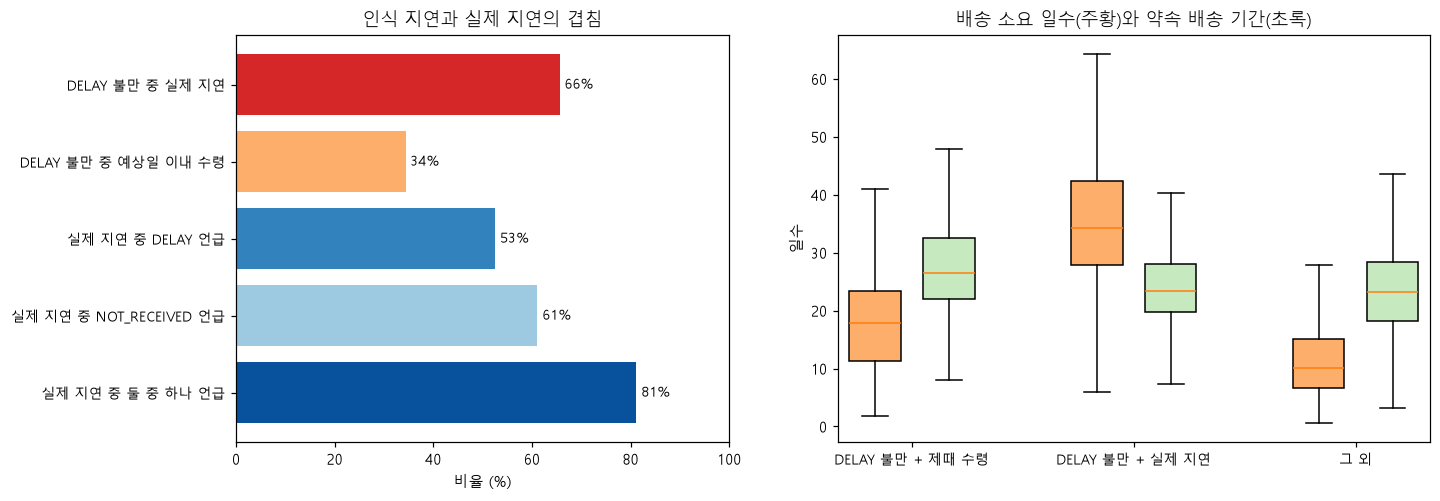

In [4]:
perceived = run_sql("q2_03_perceived_vs_actual.sql")
d_row = perceived.set_index("perspective").loc["DELAY 불만 기준"]
l_row = perceived.set_index("perspective").loc["실제 지연 기준"]
print(f"DELAY 불만 주문 {int(d_row['n_base']):,}건: 실제 지연 {d_row['share_a']:.1%} / 예상일 이내 수령 {d_row['share_b']:.1%}")
print(f"실제 지연 주문(분류 리뷰 있음) {int(l_row['n_base']):,}건: DELAY 언급 {l_row['share_a']:.1%} / "
      f"NOT_RECEIVED 언급 {l_row['share_b']:.1%} / 둘 중 하나 {l_row['share_c']:.1%}")

detail = run_sql("q2_04_delivery_days_detail.sql")
grp_order = ["DELAY 불만 + 제때 수령", "DELAY 불만 + 실제 지연", "그 외"]
summary = detail.groupby("grp")[["delivery_days", "promised_days"]].describe(percentiles=[0.25, 0.5, 0.75])
summary = summary.loc[grp_order, [(c, s) for c in ["delivery_days", "promised_days"] for s in ["count", "25%", "50%", "75%", "mean"]]]
summary.columns = [f"{'배송 소요' if c == 'delivery_days' else '약속 기간'} {s}" for c, s in summary.columns]
display(summary.round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 1.2]})
ax = axes[0]
bars = [("DELAY 불만 중 실제 지연", d_row["share_a"]), ("DELAY 불만 중 예상일 이내 수령", d_row["share_b"]),
        ("실제 지연 중 DELAY 언급", l_row["share_a"]), ("실제 지연 중 NOT_RECEIVED 언급", l_row["share_b"]),
        ("실제 지연 중 둘 중 하나 언급", l_row["share_c"])][::-1]
ax.barh(range(len(bars)), [v * 100 for _, v in bars], color=["#d62728", "#fdae6b", "#3182bd", "#9ecae1", "#08519c"][::-1])
for i, (_, v) in enumerate(bars):
    ax.text(v * 100 + 1, i, f"{v:.0%}", va="center", fontsize=9)
ax.set_yticks(range(len(bars)), [b for b, _ in bars], fontsize=9)
ax.set_xlim(0, 100)
ax.set_xlabel("비율 (%)")
ax.set_title("인식 지연과 실제 지연의 겹침")

ax = axes[1]
data = [detail.loc[detail["grp"] == g, col].dropna() for g in grp_order for col in ["delivery_days", "promised_days"]]
pos = [1, 2, 4, 5, 7, 8]
bp = ax.boxplot(data, positions=pos, widths=0.7, showfliers=False, patch_artist=True)
for patch, color in zip(bp["boxes"], ["#fdae6b", "#c7e9c0"] * 3):
    patch.set_facecolor(color)
ax.set_xticks([1.5, 4.5, 7.5], grp_order, fontsize=9)
ax.set_ylabel("일수")
ax.set_title("배송 소요 일수(주황)와 약속 배송 기간(초록)")
save(fig, "q2_perceived_vs_actual.png")
plt.show()

## 4. NOT_RECEIVED 라벨 교차 검증

NOT_RECEIVED(미수령) 라벨이 맞다면, 리뷰를 쓴 시점이 고객 수령일보다 앞서야 한다. NOT_RECEIVED가 아닌 분류 리뷰를 비교 기준으로 둔다.
`review_creation_date`는 리뷰 요청 발송일(날짜), `review_answer_timestamp`는 고객이 실제로 리뷰를 쓴 시각이다.

In [5]:
nr_check = run_sql("q2_05_not_received_check.sql")
display(pct(nr_check, ["created_before_delivery", "answered_before_delivery", "delivered_status_share"]))

,grp,n_reviews,n_no_delivery_date,n_with_delivery_date,created_before_delivery,answered_before_delivery,delivered_status_share
0,NOT_RECEIVED 아님 (비교 기준),10749,761.0,9988.0,9.7%,9.1%,92.9%
1,NOT_RECEIVED 라벨,3627,945.0,2682.0,66.7%,68.6%,73.9%


## 5. 지연 요인 (Q5 개선안 참고)

판매자 → 고객 직선 거리 구간별, 고객 주(주문 300건 이상)별 지연율.

In [6]:
by_dist = run_sql("q2_06_late_by_distance.sql")
display(pct(by_dist, ["late_rate"]).round({"avg_delivery_days": 1}))
by_state = run_sql("q2_07_late_by_state.sql")
display(pct(by_state, ["late_rate"]).round({"avg_delivery_days": 1, "avg_promised_days": 1}))

,bucket_ord,distance_bucket,n_orders,late_rate,avg_delivery_days
0,1,100km 미만,17823,4.5%,6.5
1,2,100~300km,13419,5.2%,10.0
2,3,300~600km,31486,6.8%,12.6
3,4,"600~1,000km",17903,7.1%,14.7
4,5,"1,000~2,000km",9732,9.5%,18.0
5,6,"2,000km 이상",5607,12.0%,21.2
6,7,거리 없음,477,9.4%,14.4


,customer_state,n_orders,late_rate,avg_delivery_days,avg_promised_days
0,AL,397,21.4%,24.5,32.6
1,MA,717,17.4%,21.6,30.5
2,SE,335,15.2%,21.5,30.8
3,PI,476,13.9%,19.5,30.1
4,CE,1279,13.8%,21.3,31.4
5,BA,3256,12.2%,19.3,29.4
6,RJ,12349,12.1%,15.3,26.4
7,PA,946,11.2%,23.8,37.2
8,ES,1995,10.7%,15.8,25.6
9,PB,517,10.4%,20.4,33.0


## 6. 통계 검정

### 6-1. 지연 주문 vs 제때 받은 주문의 평점: Mann-Whitney U

평점은 1~5 순서형이라 순위 기반 검정을 쓴다. 효과 크기는 rank-biserial 상관 r = 2U/(n₁n₂) − 1(지연 주문 기준, −1~1, 음수면 지연 주문의 평점이 낮음)과
"무작위로 고른 지연 주문의 평점이 제때 받은 주문보다 높을 확률" P = U/(n₁n₂)로 함께 본다(동점은 절반으로 계산).

In [7]:
model_df = run_sql("q2_08_model_data.sql")
late = model_df.loc[model_df["is_late"] == 1, "review_score"]
ontime = model_df.loc[model_df["is_late"] == 0, "review_score"]
mw = mannwhitneyu(late, ontime, alternative="two-sided")
n1, n0 = len(late), len(ontime)
r_rb = 2 * mw.statistic / (n1 * n0) - 1
print(f"지연 주문 {n1:,}건 평균 평점 {late.mean():.2f} (중앙값 {late.median():.0f}) / 제때 받은 주문 {n0:,}건 평균 {ontime.mean():.2f} (중앙값 {ontime.median():.0f})")
print(f"Mann-Whitney U = {mw.statistic:,.0f}, p = {mw.pvalue:.2e}")
print(f"rank-biserial r = {r_rb:.3f} / P(지연 주문 평점 > 제때 주문 평점) = {mw.statistic / (n1 * n0):.3f}")

지연 주문 6,381건 평균 평점 2.27 (중앙값 1) / 제때 받은 주문 89,420건 평균 4.29 (중앙값 5)
Mann-Whitney U = 103,322,078, p = 0.00e+00
rank-biserial r = -0.638 / P(지연 주문 평점 > 제때 주문 평점) = 0.181


### 6-2. 1~2점 비율 차이: 두 비율 z 검정과 95% 신뢰구간

In [8]:
k1, k0 = int(model_df.loc[model_df["is_late"] == 1, "low_score"].sum()), int(model_df.loc[model_df["is_late"] == 0, "low_score"].sum())
p1, p0 = k1 / n1, k0 / n0
z, p_z = proportions_ztest([k1, k0], [n1, n0])
ci_low, ci_high = confint_proportions_2indep(k1, n1, k0, n0, method="newcomb", compare="diff")
rr_low, rr_high = confint_proportions_2indep(k1, n1, k0, n0, method="log", compare="ratio")
print(f"1~2점 비율: 지연 {p1:.1%} ({k1:,}/{n1:,}) vs 제때 {p0:.1%} ({k0:,}/{n0:,})")
print(f"차이 {p1 - p0:+.1%}p, 95% CI [{ci_low:+.1%}p, {ci_high:+.1%}p] (Newcombe), z = {z:.1f}, p = {p_z:.2e}")
print(f"위험비 {p1 / p0:.2f}배, 95% CI [{rr_low:.2f}, {rr_high:.2f}]")

1~2점 비율: 지연 62.4% (3,982/6,381) vs 제때 9.3% (8,282/89,420)
차이 +53.1%p, 95% CI [+51.9%p, +54.3%p] (Newcombe), z = 122.8, p = 0.00e+00
위험비 6.74배, 95% CI [6.55, 6.93]


### 6-3. 로지스틱 회귀: 1~2점 여부

- 모형 1: `low_score ~ is_late + 거리(100km 단위) + 배송비 + 상품 수 + 판매자 수 + 고객 주(더미, 기준 SP)`
- 모형 2: `is_late` 대신 지연 구간(기준: 7일 이상 빠름)
- 거리를 계산할 수 없는 주문은 뺀다. 오즈비 = exp(계수), 95% 신뢰구간도 같은 방식으로 변환한다.
- 평균 한계효과(AME): 다른 변수는 그대로 두고 지연 여부만 바뀔 때 1~2점 확률이 평균 몇 %p 바뀌는지

In [9]:
mdf = model_df.dropna(subset=["distance_km", "freight_value"]).copy()
mdf["distance_100km"] = mdf["distance_km"].astype(float) / 100
mdf["freight_value"] = mdf["freight_value"].astype(float)
mdf["delay_bucket"] = pd.cut(mdf["delay_days"], bins=[-np.inf, -7, -1, 0, 3, 7, 14, np.inf], labels=BUCKETS)
print(f"회귀 표본: {len(mdf):,}건 (거리·배송비가 없어 제외 {len(model_df) - len(mdf):,}건)")

controls = "distance_100km + freight_value + n_items + n_sellers + C(customer_state, Treatment('SP'))"
m1 = smf.logit(f"low_score ~ is_late + {controls}", data=mdf).fit(disp=False, maxiter=200)
m2 = smf.logit(f"low_score ~ C(delay_bucket, Treatment('7일 이상 빠름')) + {controls}", data=mdf).fit(disp=False, maxiter=200)


def odds_table(model, keep: list[str] | None = None) -> pd.DataFrame:
    """계수를 오즈비와 95% 신뢰구간 표로 바꾼다(주 더미는 keep으로 걸러냄)."""
    ci = model.conf_int()
    out = pd.DataFrame({"오즈비": np.exp(model.params), "CI 하한": np.exp(ci[0]), "CI 상한": np.exp(ci[1]), "p값": model.pvalues})
    out = out.drop(index="Intercept")
    if keep is not None:
        out = out[[any(k in i for k in keep) for i in out.index]]
    return out


rename = {"is_late": "지연 여부(is_late)", "distance_100km": "거리(100km당)", "freight_value": "배송비(BRL당)",
          "n_items": "상품 수(1개당)", "n_sellers": "판매자 수(1명당)"}
t1 = odds_table(m1, keep=list(rename)).rename(index=rename)
print(f"모형 1: n = {int(m1.nobs):,}, McFadden 의사 R² = {m1.prsquared:.3f}")
display(t1.round(3))
ame = m1.get_margeff(at="overall").summary_frame().loc["is_late"]  # 열 순서: dy/dx, 표준오차, z, p, CI 하한, CI 상한
print(f"is_late 평균 한계효과: {ame.iloc[0]:+.1%}p (95% CI {ame.iloc[-2]:+.1%}p ~ {ame.iloc[-1]:+.1%}p)")

t2 = odds_table(m2, keep=["delay_bucket"])
t2.index = [i.split("[T.")[1].rstrip("]") for i in t2.index]
print(f"\n모형 2: n = {int(m2.nobs):,}, McFadden 의사 R² = {m2.prsquared:.3f} (기준 구간: 7일 이상 빠름)")
display(t2.round(3))

state_or = odds_table(m1, keep=["customer_state"])
state_or.index = [i.split("[T.")[1].rstrip("]") for i in state_or.index]
print("참고: 고객 주 더미 오즈비 범위(기준 SP):", f"{state_or['오즈비'].min():.2f} ~ {state_or['오즈비'].max():.2f}")

회귀 표본: 95,325건 (거리·배송비가 없어 제외 476건)


모형 1: n = 95,325, McFadden 의사 R² = 0.162


,오즈비,CI 하한,CI 상한,p값
지연 여부(is_late),17.192,16.236,18.205,0.000
거리(100km당),1.010,1.003,1.017,0.005
배송비(BRL당),1.002,1.000,1.003,0.004
상품 수(1개당),1.572,1.515,1.631,0.000
판매자 수(1명당),4.643,4.118,5.236,0.000


is_late 평균 한계효과: +25.8%p (95% CI +25.4%p ~ +26.3%p)

모형 2: n = 95,325, McFadden 의사 R² = 0.178 (기준 구간: 7일 이상 빠름)


,오즈비,CI 하한,CI 상한,p값
1~6일 빠름,1.307,1.226,1.393,0.0
예상일 당일,1.544,1.303,1.831,0.0
1~3일 지연,5.201,4.694,5.763,0.0
4~7일 지연,23.177,20.868,25.742,0.0
8~14일 지연,44.441,38.893,50.782,0.0
15일 이상 지연,39.048,34.092,44.725,0.0


참고: 고객 주 더미 오즈비 범위(기준 SP): 0.41 ~ 1.40


### 오즈비 그래프

모형 2의 지연 구간별 오즈비(기준: 7일 이상 빠름)와 모형 1의 `is_late` 오즈비. 가로축은 로그 척도이고, 점선(1)보다 오른쪽이면 1~2점 가능성이 높다.

저장: reports/figures/q2_odds_ratios.png


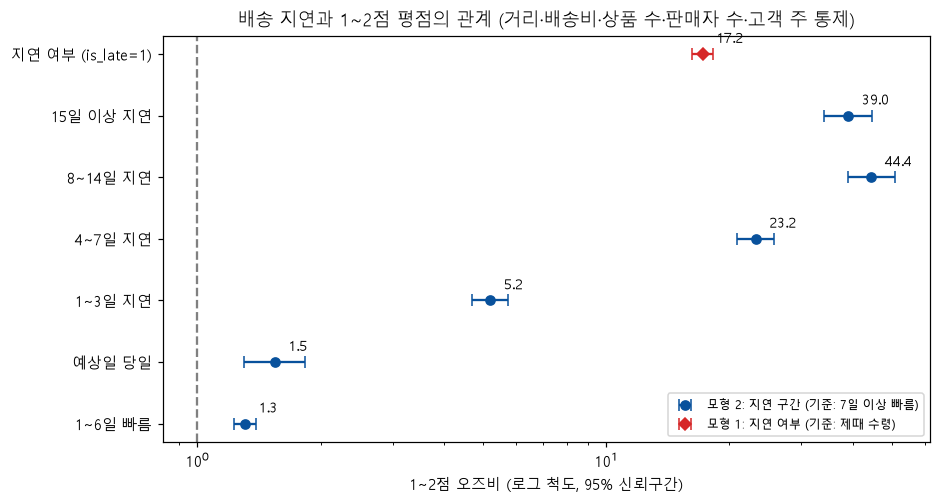

In [10]:
plot_or = t2.reindex(BUCKETS[1:])
fig, ax = plt.subplots(figsize=(9, 4.8))
y = np.arange(len(plot_or))
ax.errorbar(plot_or["오즈비"], y, xerr=[plot_or["오즈비"] - plot_or["CI 하한"], plot_or["CI 상한"] - plot_or["오즈비"]],
            fmt="o", color="#08519c", capsize=4, label="모형 2: 지연 구간 (기준: 7일 이상 빠름)")
late_or = t1.loc["지연 여부(is_late)"]
ax.errorbar([late_or["오즈비"]], [len(plot_or)], xerr=[[late_or["오즈비"] - late_or["CI 하한"]], [late_or["CI 상한"] - late_or["오즈비"]]],
            fmt="D", color="#d62728", capsize=4, label="모형 1: 지연 여부 (기준: 제때 수령)")
for yi, v in zip(list(y) + [len(plot_or)], list(plot_or["오즈비"]) + [late_or["오즈비"]]):
    ax.text(v * 1.08, yi + 0.18, f"{v:.1f}", fontsize=9)
ax.axvline(1, color="gray", linestyle="--")
ax.set_xscale("log")
ax.set_yticks(list(y) + [len(plot_or)], list(plot_or.index) + ["지연 여부 (is_late=1)"])
ax.set_xlabel("1~2점 오즈비 (로그 척도, 95% 신뢰구간)")
ax.set_title("배송 지연과 1~2점 평점의 관계 (거리·배송비·상품 수·판매자 수·고객 주 통제)")
ax.legend(loc="lower right", fontsize=8)
save(fig, "q2_odds_ratios.png")
plt.show()

## 정리

핵심 발견, 검정 결과 요약, 해석 주의점은 `reports/analysis/q2_delivery_delay.md`에 정리했다.